In [1]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import load_iris

iris = load_iris()
iris_scaled = StandardScaler().fit_transform(iris.data)


In [2]:
lda = LinearDiscriminantAnalysis(n_components= 2)
lda.fit(iris_scaled, iris.target)
iris_lda = lda.transform(iris_scaled)
print(iris_lda.shape)


(150, 2)


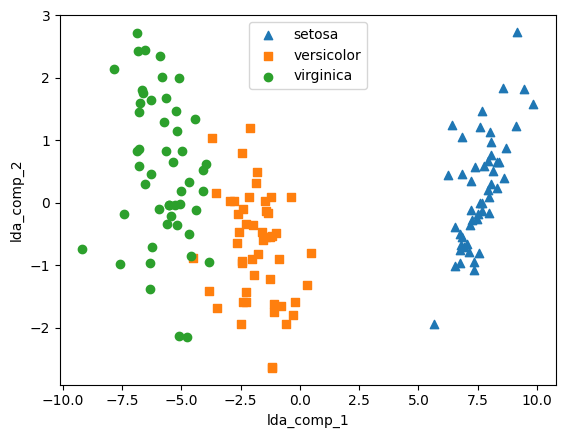

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

lda_columns = ["lda_comp_1", "lda_comp_2"]
irisDF_lda = pd.DataFrame(iris_lda , columns = lda_columns)
irisDF_lda["target"] = iris.target

markers = ["^" , "s", "o"]

for i, marker in enumerate(markers):
    x_axis_data = irisDF_lda[irisDF_lda["target"] == i]["lda_comp_1"]
    y_axis_data = irisDF_lda[irisDF_lda["target"] == i]["lda_comp_2"]
    plt.scatter(x_axis_data, y_axis_data, marker=marker, label=iris.target_names[i])

plt.legend()
plt.xlabel("lda_comp_1")
plt.ylabel("lda_comp_2")
plt.show()

Text(0.5, 0, ' :')

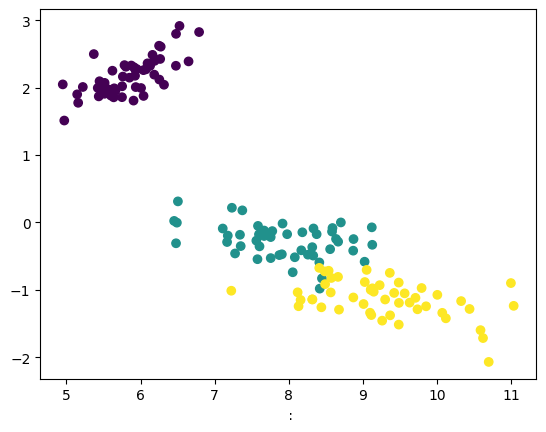

In [5]:
from sklearn.decomposition import TruncatedSVD,PCA


iris  = load_iris()
iris_ftrs = iris.data
tsvd = TruncatedSVD(n_components= 2)
tsvd.fit(iris_ftrs)
iris_tsvd = tsvd.transform(iris_ftrs)

plt.scatter (x = iris_tsvd[:,0],y = iris_tsvd[: , 1], c = iris.target)
plt.xlabel(" :")
plt.xlabel(" :")

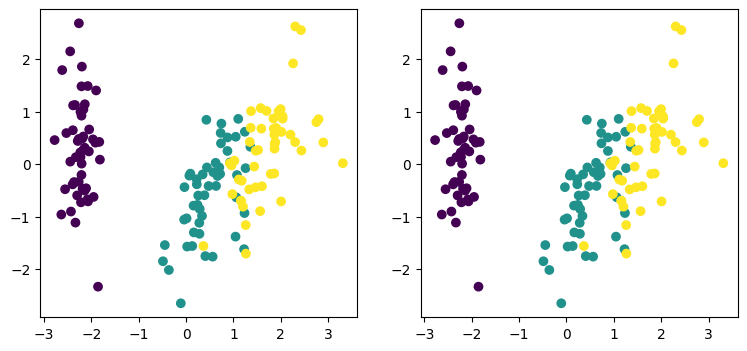

In [8]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

iris_scaled = StandardScaler().fit_transform(iris_ftrs)
tsvd = TruncatedSVD(n_components = 2)
tsvd.fit(iris_scaled)
iris_tsvd = tsvd . transform(iris_scaled)

pca = PCA(n_components = 2)
pca.fit(iris_scaled)
iris_pca = pca.transform(iris_scaled)

fig, (ax1, ax2) = plt.subplots(figsize = (9,4),ncols=2)

ax1.scatter (x = iris_tsvd[:,0], y = iris_tsvd[ : , 1], c = iris.target)
ax2.scatter (x = iris_pca[:,0], y = iris_pca[ : , 1], c = iris.target)




In [10]:
import numpy as np
# 셀 5: 변환 결과와 성분 비교
print("변환 결과 차이의 평균:", np.mean(iris_pca - iris_tsvd))
print("성분 행렬 차이:\n", pca.components_ - tsvd.components_)

변환 결과 차이의 평균: 2.334394251975643e-15
성분 행렬 차이:
 [[-1.11022302e-16 -1.11022302e-16  1.11022302e-16  0.00000000e+00]
 [-2.77555756e-16 -1.11022302e-16  2.22044605e-16 -2.22044605e-16]]


In [12]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler
# 셀 6: NMF

# NMF는 음수 입력을 허용하지 않으므로 원본 특성을 0~1 범위로 변환합니다.
iris_nonnegative = MinMaxScaler().fit_transform(iris_ftrs)

nmf = NMF(n_components=2, init="nndsvda", random_state=42, max_iter=1000)
iris_nmf = nmf.fit_transform(iris_nonnegative)

plt.scatter(
    iris_nmf[:, 0],
    iris_nmf[:, 1],
    c=iris_target,
    cmap="viridis"
)
plt.xlabel("nmf_component_1")
plt.ylabel("nmf_component_2")
plt.title("Iris NMF")
plt.colorbar(label="target")
plt.show()

NameError: name 'NMF' is not defined